# Navier-Stokes surrogate — reconstructing a flow, and where it fails

Our second PDE benchmark is the **lid-driven cavity**: incompressible flow in a box whose top lid
slides at $U=1$, driving a primary vortex. We solve it once with the Chapter-1 projection solver,
then train a black-box surrogate $(x,y)\mapsto(u,v)$ from velocity samples in the **lower part of
the cavity only** --- as if our sensors could not reach the top. We then ask it to fill in the
region it never saw, right under the moving lid. Inside the sampled region the reconstruction is
excellent (interpolation); in the unseen boundary layer it is badly wrong (extrapolation), because
nothing told the surrogate a thin high-shear layer lives there. Partial observations plus a black
box is a classic digital-twin trap.

**The ground truth.** The benchmark integrates the incompressible Navier--Stokes equations
$$ \frac{\partial\boldsymbol u}{\partial t} + (\boldsymbol u\cdot\nabla)\boldsymbol u
   = -\frac1\rho\nabla p + \nu\,\nabla^2\boldsymbol u, \qquad \nabla\cdot\boldsymbol u = 0, $$
with a Chorin projection method (predictor $\to$ pressure-Poisson $\to$ divergence-free corrector)
on a $61\times61$ grid, density $\rho=1$ and kinematic viscosity $\nu = UL/\mathrm{Re}$.
**BC:** no-slip ($\boldsymbol u=\boldsymbol 0$) on the left, right and bottom walls, and a moving
top lid $u=U=1,\ v=0$. **IC:** fluid at rest, $\boldsymbol u=\boldsymbol 0$. **Parameters:**
$\mathrm{Re}=400$, $L=1$. **The split, in space:** "sensors" observe only $y\le0.65$; those points are split at random
70 / 15 / 15 % into training, validation (used only to choose when to stop training) and an
in-range test that measures **interpolation**, and the entire unobserved band $y>0.65$ — which
contains the thin, fast lid boundary layer — is the out-of-range test that measures **extrapolation**.

cavity solved at Re=400 on 61x61;  max speed = 1.000
rows (x, y) -> (u, v):  train=1708  validation=366  test-in=366  test-out (unseen lid band)=1281


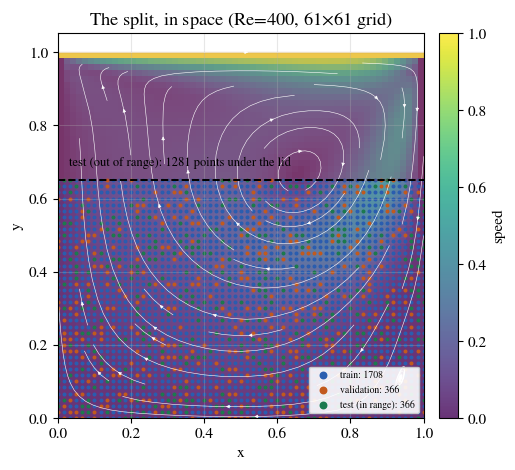

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, matplotlib.pyplot as plt
from pyutils.nets import MLP
from pyutils import set_plot_style, save_dual, fg, muted
from pyutils.benchmarks.navier_stokes import lid_driven_cavity
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)
set_plot_style()
FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

# --- ground truth: one lid-driven-cavity solve (Chapter-1 projection method) ---
NX = 61; RE = 400.0; L = 1.0
dx = L / (NX - 1); dt = 0.15 * dx
x = np.linspace(0, L, NX); Xg, Yg = np.meshgrid(x, x, indexing='ij')
_, _, u, v, p = lid_driven_cavity(nx=NX, ny=NX, nt=2500, nit=80, Re=RE, dt=dt)
speed = np.sqrt(u**2 + v**2)
print(f'cavity solved at Re={RE:.0f} on {NX}x{NX};  max speed = {speed.max():.3f}')

# --- the split, in space: sensors only below y = YCUT; the lid band is never seen ---
YCUT = 0.65
xs, ys = Xg.ravel(), Yg.ravel(); U, Vv = u.ravel(), v.ravel()
seen = ys <= YCUT; unseen = ys > YCUT
rng = np.random.default_rng(1)
idx = rng.permutation(np.where(seen)[0]); n_tr, n_va = int(0.70*len(idx)), int(0.15*len(idx))
train_mask  = np.zeros_like(seen); train_mask[idx[:n_tr]] = True                 # fit
val_mask    = np.zeros_like(seen); val_mask[idx[n_tr:n_tr+n_va]] = True          # choose when to stop
interp_mask = np.zeros_like(seen); interp_mask[idx[n_tr+n_va:]] = True           # test, in range
print(f'rows (x, y) -> (u, v):  train={train_mask.sum()}  validation={val_mask.sum()}  '
      f'test-in={interp_mask.sum()}  test-out (unseen lid band)={unseen.sum()}')

def plot_ddm_ns_split():
    fig, ax = plt.subplots(figsize=(6.4, 5.0))
    im = ax.imshow(speed.T, origin='lower', extent=[0, 1, 0, 1], cmap='viridis', vmin=0, vmax=1, aspect='equal', alpha=0.8)
    ax.streamplot(x, x, u.T, v.T, color='white', density=0.6, linewidth=0.4, arrowsize=0.5)
    for m, c, tag in [(train_mask, 'C0', 'train'), (val_mask, 'C1', 'validation'), (interp_mask, 'C2', 'test (in range)')]:
        ax.scatter(xs[m], ys[m], s=3.5, color=c, label=f'{tag}: {m.sum()}')
    ax.fill_between([0, 1], YCUT, 1, color='C3', alpha=0.2); ax.axhline(YCUT, ls='--', color=fg(), lw=1.4)
    ax.text(0.03, 0.69, f'test (out of range): {unseen.sum()} points under the lid', color=fg(), fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label='speed')
    ax.set(xlabel='x', ylabel='y', title=f'The split, in space (Re={RE:.0f}, {NX}$\\times${NX} grid)')
    ax.legend(loc='lower right', fontsize=7, markerscale=2.5, framealpha=0.9)

save_dual(plot_ddm_ns_split, 'ddm_ns_split', FIG); plt.show()

The solve reports a **maximum speed of 1.000**, reached only at the lid itself — confirming the moving-wall BC drives the flow — and the split is **1,708 training, 366 validation and 366 in-range test points below the cut, and 1,281 out-of-range points in the band above it**. The figure is the data card: white streamlines trace the single primary vortex (its centre sits high and to the right, near $(0.6,\,0.75)$), colour is speed, and the points below the dashed line at $y=0.65$ carry the split colours. Almost all the fast fluid — the bright layer skimming the top lid and the jet descending the right wall — lives **above** the cut, in the shaded band no set below the line ever samples. Nothing in the training, validation or in-range test data hints that $|\boldsymbol u|$ jumps to $1$ at the top.

## Train below the line, predict above it

The surrogate `MLP([2, 64, 64, 64, 2])` maps $(x,y)\to(\hat u,\hat v)$; inputs and the two velocity targets are standardized on the **training points only**, and we minimize the mean-squared velocity error
$$ \mathcal L(\theta)=\frac1N\sum_i\big\lVert(\hat u_i,\hat v_i)-(u_i,v_i)\big\rVert^2 $$
with up to 5000 full-batch Adam steps (`lr=2e-3`), keeping the parameters with the **lowest validation loss** (checked every 100 steps). We then score per-point velocity RMSE on the validation set, on the in-range test points (interpolation) and on the out-of-range band above the cut (extrapolation), and map the error over the whole cavity.

final train loss 2.42e-04   best validation loss 3.02e-05 at step 4900
RMSE  validation = 0.0006   test-in (held-out, below cut) = 0.0006   test-out (unseen lid band) = 0.2877
extrapolation error is 497x the interpolation error


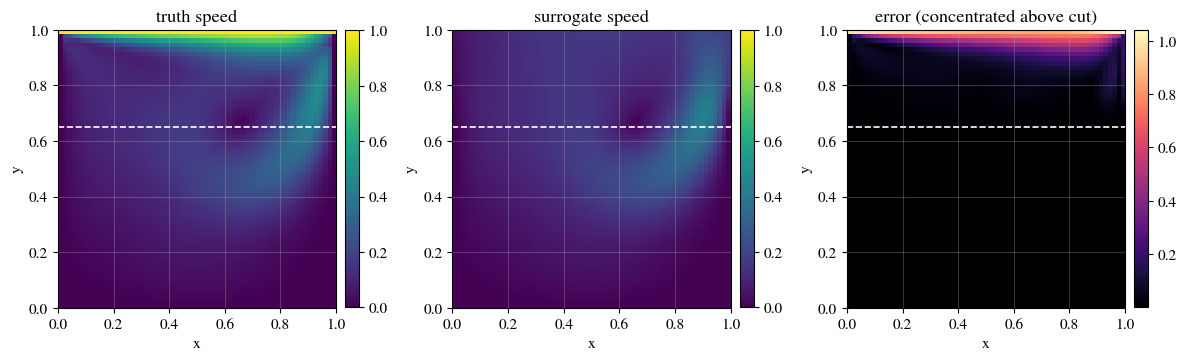

In [2]:
X = np.c_[xs, ys]; Yt_all = np.c_[U, Vv]
Xm, Xs = X[train_mask].mean(0), X[train_mask].std(0)                   # standardize on the training rows only
Ym, Ys = Yt_all[train_mask].mean(0), Yt_all[train_mask].std(0)
norm = lambda A: torch.tensor((A - Xm) / Xs); tnorm = lambda B: torch.tensor((B - Ym) / Ys)
Xt, Yt = norm(X[train_mask]), tnorm(Yt_all[train_mask]); Xv, Yv = norm(X[val_mask]), tnorm(Yt_all[val_mask])

torch.manual_seed(0); net = MLP([2, 64, 64, 64, 2]); opt = torch.optim.Adam(net.parameters(), lr=2e-3)
best, best_step, best_state = np.inf, 0, None
for step in range(1, 5001):                                            # keep the best-validation parameters
    opt.zero_grad(); loss = ((net(Xt) - Yt)**2).mean(); loss.backward(); opt.step()
    if step % 100 == 0:
        with torch.no_grad(): lva = float(((net(Xv) - Yv)**2).mean())
        if lva < best: best, best_step, best_state = lva, step, {k: v.clone() for k, v in net.state_dict().items()}
net.load_state_dict(best_state)
print(f'final train loss {float(loss.detach()):.2e}   best validation loss {best:.2e} at step {best_step}')

with torch.no_grad():
    pred = net(norm(X)).numpy() * Ys + Ym
err = np.sqrt(((pred - Yt_all)**2).sum(1))          # per-point velocity error
rms = lambda m: float(np.sqrt(np.mean(err[m]**2)))
e_val, e_interp, e_extrap = rms(val_mask), rms(interp_mask), rms(unseen)
print(f'RMSE  validation = {e_val:.4f}   test-in (held-out, below cut) = {e_interp:.4f}   '
      f'test-out (unseen lid band) = {e_extrap:.4f}')
print(f'extrapolation error is {e_extrap/e_interp:.0f}x the interpolation error')

spd_pred = np.sqrt(pred[:, 0]**2 + pred[:, 1]**2).reshape(NX, NX)
err2d = err.reshape(NX, NX)

def plot_ddm_ns_cliff():
    fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
    for a, F, ttl in [(ax[0], speed, 'truth speed'),
                       (ax[1], spd_pred, 'surrogate speed')]:
        im = a.imshow(F.T, origin='lower', extent=[0, 1, 0, 1], cmap='viridis',
                      vmin=0, vmax=1.0, aspect='equal')
        a.axhline(YCUT, ls='--', color='white', lw=1.2)
        a.set(title=ttl, xlabel='x', ylabel='y')
        fig.colorbar(im, ax=a, fraction=0.046, pad=0.03)
    im = ax[2].imshow(err2d.T, origin='lower', extent=[0, 1, 0, 1], cmap='magma', aspect='equal')
    ax[2].axhline(YCUT, ls='--', color='white', lw=1.2)
    ax[2].set(title='error (concentrated above cut)', xlabel='x', ylabel='y')
    fig.colorbar(im, ax=ax[2], fraction=0.046, pad=0.03)
    plt.tight_layout()

save_dual(plot_ddm_ns_cliff, 'ddm_ns_cliff', FIG); plt.show()
assert e_extrap > 20 * e_interp      # reconstruction fails in the unobserved boundary layer

Validation picks step 4900 of 5000, and the three held-out numbers tell the story: **validation RMSE 0.0006, in-range test RMSE 0.0006** — the two agree, as they should for two samples of the same region — versus **out-of-range RMSE 0.2877** in the unseen band, a **$\sim\!500\times$** jump (the `assert` demands only $>20\times$). The three panels show it: *truth* (left) has the bright lid layer feeding the vortex; the *surrogate* (middle) reproduces the flow perfectly below the dashed cut but flattens to near-zero above it, completely missing the yellow lid boundary layer; the *error* map (right) is black everywhere below the cut and lights up only in the thin band along the very top, exactly where no sensor reached. The black box smoothly extends the interior flow upward, with no notion that a high-shear layer is waiting there and no signal that it is extrapolating.

## What the surrogate gets wrong, measured

The surrogate was never told that the lid moves. Check its output against two things the physics fixes and the data below the cut does not: the **boundary condition** at the lid, $u(x,1)=U=1$, and the **speed** the flow must reach in the band just beneath it.

In [3]:
# --- measured: physics the surrogate was never told, checked in the unseen band ------
up, vp = pred[:, 0].reshape(NX, NX), pred[:, 1].reshape(NX, NX)
band = Yg > YCUT
print(f'mean u along the lid (y=1):         solver {u[1:-1, -1].mean():.3f}   '
      f'surrogate {up[1:-1, -1].mean():.3f}   (lid speed U=1)')
print(f'max speed in the unseen band:       solver {speed[band].max():.3f}   '
      f'surrogate {np.sqrt(up**2 + vp**2)[band].max():.3f}')


mean u along the lid (y=1):         solver 1.000   surrogate 0.095   (lid speed U=1)
max speed in the unseen band:       solver 1.000   surrogate 0.433


The surrogate predicts a **mean $u$ of 0.10 along the lid**, where the boundary condition says $1.0$, and its **fastest speed in the unseen band is 0.43** against the solver's $1.0$. That is the moving-lid boundary condition violated by a factor of ten, with nothing in the training loss to object: every point the network was fitted to lies below the cut, and a smooth upward continuation of the interior flow is the most plausible thing the data allows. A model fitted to samples has no way to know that the top wall is moving.

**Lesson.** Where it has data the surrogate reconstructs the flow almost exactly, and it is far
cheaper to evaluate than the Navier-Stokes solver. But it has no momentum equation, so in the
unobserved band it simply extends the smooth interior flow and completely misses the thin lid shear
layer --- the error there is hundreds of times larger, with no warning. What determines the flow
above the sensor line is the momentum equation together with the moving lid, and neither is in the
training data. A model that sees only samples has no route to that information.